In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import keras
from keras import layers
import tensorflow as tf

SEED = 42
keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow at once
print(tf.config.list_physical_devices("GPU"))

option = "filtered"
n_mels = 64
label_type = "patient" # patient or channel

folder = Path("data/processed/cnn_2d") / option / f"mel_{n_mels}"

x_trainval = np.load(folder / "X_trainval_2d.npy", mmap_mode="r")
y_patient = np.load(folder / "y_patient_trainval_2d.npy")
y_channel = np.load(folder / "y_channel_trainval_2d.npy")
groups_trainval = np.load(folder / "groups_trainval_2d.npy")
meta_trainval = pd.read_csv(folder / "meta_trainval_2d.csv")

y_trainval = y_patient if label_type == "patient" else y_channel

assert x_trainval.shape[1:] == (n_mels, 157, 1)
assert len(x_trainval) == len(y_trainval) == len(y_patient) == len(groups_trainval) == len(meta_trainval)
assert np.array_equal(groups_trainval, meta_trainval["Patient ID"])
assert set(meta_trainval["fold"]) == set(range(5))

I0000 00:00:1794045289.601646 1277125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794045289.974424 1277125 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794045292.169131 1277125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### TODOs
- validation loss com pessos corretos
- hard coded rules, unstable training... abmil como possivel solução?
- treino nos dados de treino e usar no teste? media dos epochs na cv?
- criar e guardar configs de modelos, comparar o filtered vs unfiltered vs deleting low quality audios, 64vs128 mel bands... estou a pensar usar mlflow...
- data augmentation: ruido, mascaras/tirar intervalos de frequencia/tempo, sobrepor janelas?  
    "Sim, janelas de 5 segundos com passo de 2.5 segundos são uma alternativa simples ao crop aleatório. Usar mais sobreposição em Present e Unknown seria uma forma de aumentar a representação dessas classes no treino.
    Mas as janelas partilham áudio: aumentamos os exemplos, não o número de pacientes nem a informação independente. Também podemos acabar por repetir mais exemplos ruidosos de Unknown.
    Eu testaria isso apenas no treino de cada fold, mantendo as janelas de validação iguais às da baseline. O agrupamento por pessoa mantém-se obrigatório. Assim percebemos se essa amostragem melhora a weighted accuracy por paciente, sem mudar também os dados usados para avaliar."
- transfer learning? com um transformer? ou tem que ser uma cnn? perguntar ao professor
- gridsearch em alguns parametros? **demora mt tempo, se fizermos seria só no final**

## CNN Architecture

This baseline CNN is inspired by the winners of the 2022 competition: [article](https://cinc.org/archives/2022/pdf/CinC2022-165.pdf).

We use four convolutional layers with 32, 32, 32 and 64 filters. Each is followed by batch normalization and ReLU. The first two blocks use max pooling to reduce the dimensions, and the two middle blocks use dropout to reduce overfitting.

We use He weight initialization because it is better suited for ReLU.

The last convolutional layer has 64 filters. We use `GlobalAveragePooling2D` to average each of the 64 feature maps, giving 64 values. These go into a dense layer with three neurons and softmax activation, which outputs a probability for each class.


In [2]:
from keras.initializers import HeNormal

def build_cnn():
    cnn = keras.Sequential([
        keras.Input(shape=x_trainval.shape[1:]),

        layers.Conv2D(32, kernel_size=3, padding="same", kernel_initializer=HeNormal),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(32, kernel_size=3, padding="same", kernel_initializer=HeNormal),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.1),

        layers.Conv2D(32, kernel_size=3, padding="same",kernel_initializer=HeNormal),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.1),

        layers.Conv2D(64, kernel_size=3, padding="same", kernel_initializer=HeNormal),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.GlobalAveragePooling2D(),
        layers.Dense(3, activation="softmax"),
    ])
    return cnn

build_cnn().summary()

I0000 00:00:1794045300.444291 1277125 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2174 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 157, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 157, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 157, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 78, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 39, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 39, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 39, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 39, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,147 (149.01 KB)

 Trainable params: 37,827 (147.76 KB)

 Non-trainable params: 320 (1.25 KB)

## Patient-level predictions

The CNN predicts a class for each window, but we need one prediction per patient. We group the window predictions using their patient IDs and apply this rule:

- If any window predicts `Present`, the patient is classified as `Present`.
- Otherwise, if any window predicts `Unknown`, the patient is classified as `Unknown`.
- If all windows predict `Absent`, the patient is classified as `Absent`.

We then calculate weighted accuracy at the patient level, using weights of 5 for `Present`, 3 for `Unknown` and 1 for `Absent`.

In [3]:
def aggregate_predictions(predictions):
    if predictions.eq(1).any():
        return 1
    if predictions.eq(2).any():
        return 2
    return 0

def evaluate_patients(model, x, labels, groups):
    predictions = model.predict(x, batch_size=batch_size, verbose=0).argmax(axis=1)
    windows = pd.DataFrame({
        "patient_id": groups,
        "true": labels,
        "predicted": predictions,
    })

    patients = windows.groupby("patient_id").agg(
        true=("true", "first"),
        predicted=("predicted", aggregate_predictions),
    )

    weights = patients["true"].map(class_weights)
    correct = patients["true"].eq(patients["predicted"])
    score = float(np.average(correct, weights=weights))
    return patients, score

In [6]:
# learning_rate = 1e-3
learning_rate = 1e-4 # with 0.001 it's too unstable
batch_size = 24
epochs = 100
patience = 20
class_weights = {0: 1.0, 1: 5.0, 2: 3.0}

class PatientValidation(keras.callbacks.Callback):
    def __init__(self, x, labels, groups):
        super().__init__()
        self.x, self.labels, self.groups = x, labels, groups

    def on_epoch_end(self, epoch, logs=None):
        _, score = evaluate_patients(self.model, self.x, self.labels, self.groups)
        logs["val_patient_wa"] = score

## Training

We use five-fold cross-validation on the training/validation data.

We use Adam and cross-entropy with class weights of 5 for Present, 3 for Unknown and 1 for Absent. Training runs for up to 100 epochs, with a batch size of 24. Early stopping monitors patient-level weighted accuracy on validation data, with patience of 20 epochs.



In [ ]:
#took 35 mins
def train_fold(fold):
    keras.backend.clear_session()

    train_rows = meta_trainval["fold"].ne(fold).to_numpy()
    val_rows = meta_trainval["fold"].eq(fold).to_numpy()

    x_train, y_train = x_trainval[train_rows], y_trainval[train_rows]
    x_val, y_val = x_trainval[val_rows], y_trainval[val_rows]
    patient_labels = y_patient[val_rows]
    patient_ids = groups_trainval[val_rows]

    model = build_cnn()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_patient_wa",
        mode="max",
        patience=patience,
        restore_best_weights=True,
    )

    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weights,
        callbacks=[PatientValidation(x_val, patient_labels, patient_ids), early_stopping],
    )

    patients, score = evaluate_patients(model, x_val, patient_labels, patient_ids)
    return {
        "history": history.history,
        "patients": patients,
        "weighted_accuracy": score,
    }

results = {}
for fold in range(5):
    print(f"\nFold {fold + 1}/5")
    results[fold] = train_fold(fold)
    print(f"Patient-level weighted accuracy: {results[fold]['weighted_accuracy']:.4f}")


Fold 1/5
Epoch 1/100


I0000 00:00:1794045439.947667 1277125 service.cc:154] XLA service 0x55d843717b80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794045439.947687 1277125 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.4.0[615.78.8]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.0)
I0000 00:00:1794045439.998560 1277125 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794045440.702675 1277125 cuda_dnn.cc:442] Loaded cuDNN version 92800


 10/385 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.7792 - loss: 2.0599

I0000 00:00:1794045445.003680 1277125 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


385/385 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.6331 - loss: 1.7016 - val_accuracy: 0.7982 - val_loss: 0.6261 - val_patient_wa: 0.6298
Epoch 2/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6064 - loss: 1.5138 - val_accuracy: 0.8158 - val_loss: 0.5635 - val_patient_wa: 0.6263
Epoch 3/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6400 - loss: 1.4423 - val_accuracy: 0.8200 - val_loss: 0.5292 - val_patient_wa: 0.6367
Epoch 4/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6607 - loss: 1.3846 - val_accuracy: 0.8321 - val_loss: 0.5331 - val_patient_wa: 0.6782
Epoch 5/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6784 - loss: 1.3399 - val_accuracy: 0.8409 - val_loss: 0.5200 - val_patient_wa: 0.7059
Epoch 6/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.6864 - loss: 1.3064 - val_accuracy: 0.8342 - val_loss: 0.5573 - val_patient_wa: 0.6609
Epoch 7/100
385/385 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.6990 - loss: 

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_fold(fold, result):
    h = result["history"]
    patients = result["patients"]
    epoch_numbers = np.arange(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmax(h["val_patient_wa"])) + 1
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(epoch_numbers, h["loss"], label="Train")
    axes[0].plot(epoch_numbers, h["val_loss"], label="Validation")
    axes[0].set_title("Window loss")
    axes[0].set_ylabel("Cross-entropy")

    axes[1].plot(epoch_numbers, h["val_patient_wa"], label="Validation")
    axes[1].axvline(best_epoch, color="grey", linestyle="--", label="Selected epoch")
    axes[1].set_title("Patient-level weighted accuracy")
    axes[1].set_ylabel("Weighted accuracy")

    for ax in axes[:2]:
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True)

    # Rows = predicted labels, columns = true labels.
    cm = confusion_matrix(patients["true"], patients["predicted"], labels=[1, 2, 0]).T
    ConfusionMatrixDisplay(cm, display_labels=["Present", "Unknown", "Absent"]).plot(ax=axes[2], colorbar=False)
    axes[2].set_xlabel("True label")
    axes[2].set_ylabel("Predicted label")
    axes[2].set_title("Patient-level confusion matrix")

    fig.suptitle(f"Fold {fold + 1} — weighted accuracy: {result['weighted_accuracy']:.4f}")
    fig.tight_layout()
    plt.show()

the validation loss is much lower because its not using the weights

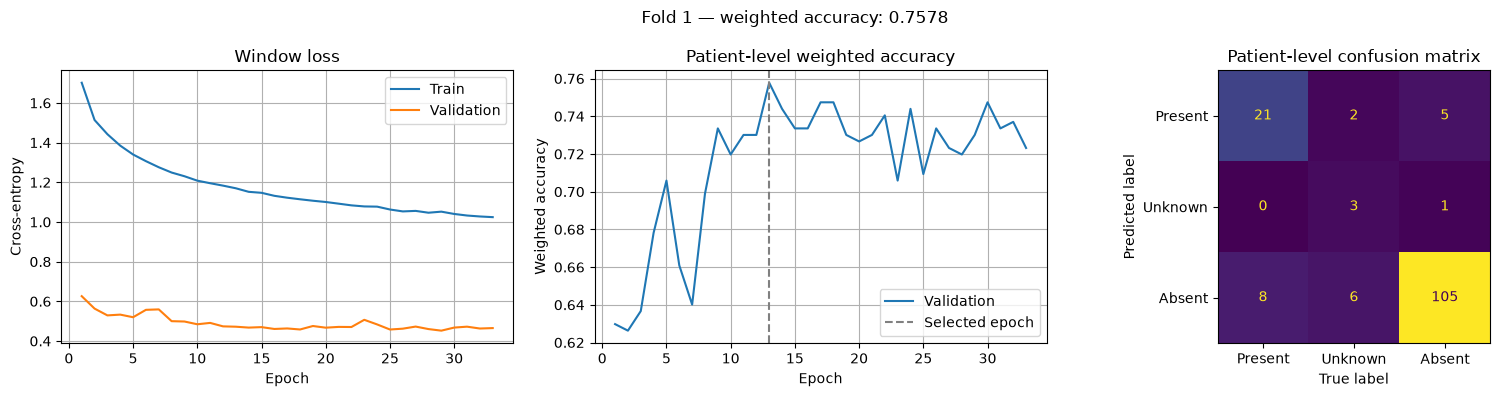

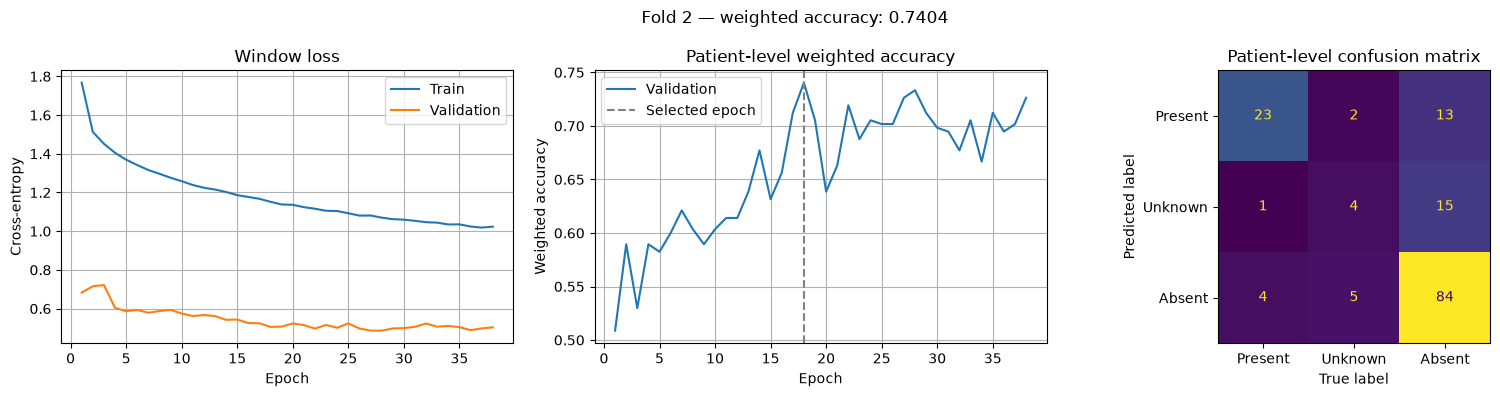

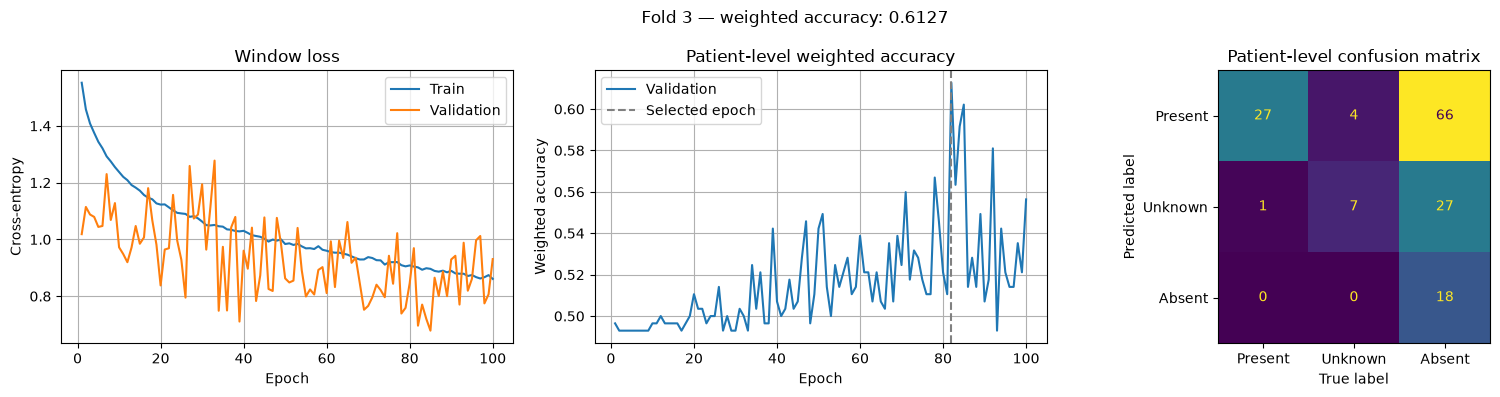

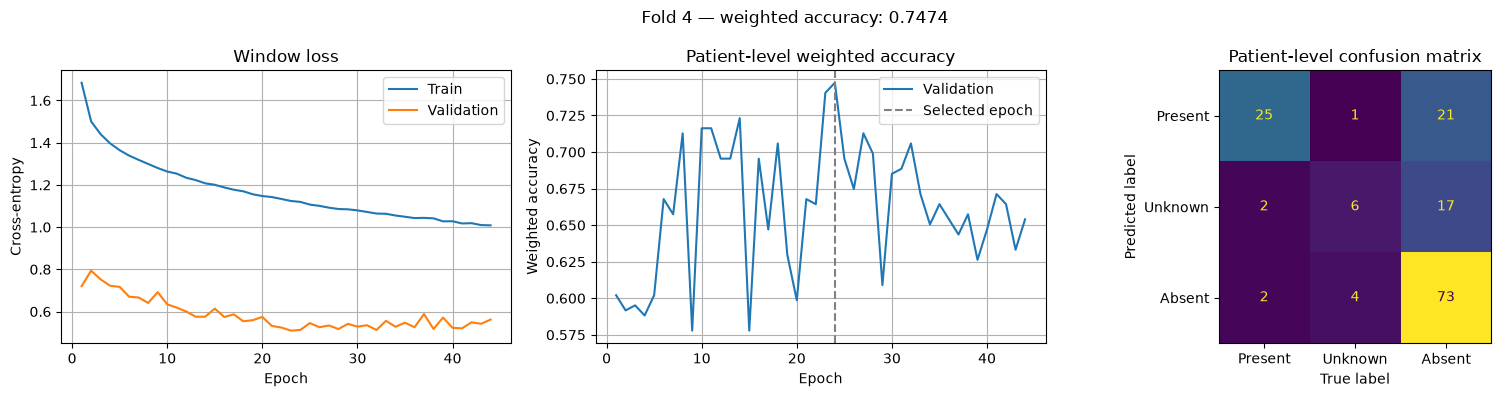

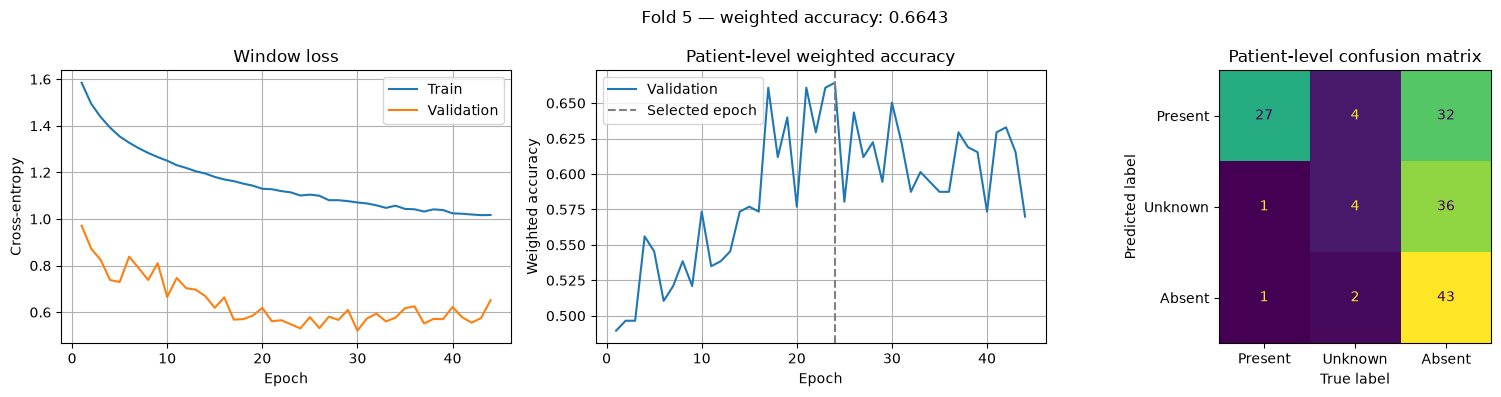

CV patient-level weighted accuracy: 0.7045 ± 0.0633


In [9]:
for fold, result in results.items():
    plot_fold(fold, result)

scores = [result["weighted_accuracy"] for result in results.values()]
print(f"CV patient-level weighted accuracy: {np.mean(scores):.4f} ± {np.std(scores, ddof=1):.4f}")